# 04 · Evaluación final · «BiciPrevisión» · equipo «Las Palmeras» (entrega de referencia, Sprint 16)

**Qué hace este cuaderno:** evalúa en el test (nov–dic 2012) el modelo candidato del Sprint 15 **con su incertidumbre**, enseña **dónde falla** (por subgrupos y por días), prueba **tres mitigaciones** eligiendo con validación cruzada sobre el entrenamiento, mide el **antes y el después**, cierra los riesgos que dependen de datos (Sandy, clima con error, horas sin fila) y guarda lo que necesita el demostrador.

**El test, una sola vez:** el modelo y las cifras son los del Sprint 15 (el cuaderno comprueba que el MAE coincide). Aquí solo se calculan más cosas con las mismas predicciones. **Nada de lo que sale aquí se usa para volver a elegir modelo**: las decisiones de mitigación se toman con la validación cruzada del entrenamiento; el test solo mide el antes y el después.

**Cómo se ejecuta:** necesita `../../sprint-15/modelo_candidato.joblib` y `metadatos.json`. *Entorno de ejecución → Reiniciar y ejecutar todo* (1–2 minutos). `SEMILLA = 42`.

## 0. Preparación

In [1]:
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


In [2]:
import sys, json, random
import joblib
import sklearn
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from pandas.tseries.holiday import USFederalHolidayCalendar

random.seed(SEMILLA)
ENTORNO = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__}
print(json.dumps(ENTORNO))
for carpeta in ("../docs/figuras", "../demostrador/modelo"):
    os.makedirs(carpeta, exist_ok=True)
COLOR = {"real": "#4A5568", "modelo": "#0F7F7F", "base": "#B9B29E", "alerta": "#C23B1F"}

{"python": "3.13.18", "numpy": "2.5.3", "pandas": "2.3.3", "scikit-learn": "1.9.1"}


## 1. Datos y modelo candidato

In [3]:
horas = pd.read_csv(dato("bicis_horas.csv"), parse_dates=["dteday"])
horas["ts"] = horas["dteday"] + pd.to_timedelta(horas["hr"], unit="h")
indice = pd.date_range(horas["ts"].min(), horas["ts"].max(), freq="h")
serie = horas.set_index("ts").reindex(indice)           # una fila por hora, sin saltos
serie["hueco"] = serie["cnt"].isna()                    # horas que no están en el CSV (nadie alquiló)
serie["cnt"] = serie["cnt"].fillna(0)                   # decisión de limpieza: sin fila = 0 bicis alquiladas
for c in ["holiday", "workingday"]:
    serie[c] = serie.groupby(serie.index.normalize())[c].transform("max")   # el día es laborable o festivo en todas sus horas
for c in ["weathersit", "temp", "atemp", "hum", "windspeed"]:
    serie[c] = serie[c].ffill()                         # el clima de una hora sin fila se toma de la anterior
serie["hr"], serie["weekday"], serie["mnth"] = serie.index.hour, serie.index.dayofweek, serie.index.month

CLIMA = ["weathersit", "temp", "atemp", "hum", "windspeed"]

def construir_variables(s):
    """Variables para predecir cada hora de MAÑANA con lo que se sabe a las 23:00 de hoy (retrasos de 24 h o más)."""
    x = pd.DataFrame(index=s.index)
    x["hr"], x["weekday"], x["mnth"] = s["hr"], s["weekday"], s["mnth"]
    x["holiday"], x["workingday"] = s["holiday"], s["workingday"]
    x["lag_24"] = s["cnt"].shift(24)                                         # la misma hora de hoy
    x["lag_168"] = s["cnt"].shift(168)                                       # la misma hora de la semana anterior
    x["media4sem"] = sum(s["cnt"].shift(168 * k) for k in (1, 2, 3, 4)) / 4  # media de esa hora en las 4 semanas anteriores
    x["nivel_7d"] = s["cnt"].shift(24).rolling(168).mean()                   # nivel medio de los últimos 7 días
    for c in CLIMA:
        x[c] = s[c]                                                          # clima de esa hora (en producción, la previsión)
    return x

# Partición por fechas (decidida antes de ver ningún resultado): lo último es el examen
FIN_ENTRENAMIENTO, FIN_VALIDACION = "2012-09-01", "2012-11-01"
x = construir_variables(serie)
y = serie["cnt"]
ok = x.notna().all(axis=1)                                   # las primeras 4 semanas no tienen todos los retrasos
x, y = x[ok], y[ok]
m_ent = x.index < FIN_ENTRENAMIENTO
m_val = (x.index >= FIN_ENTRENAMIENTO) & (x.index < FIN_VALIDACION)
m_test = x.index >= FIN_VALIDACION
hora_punta = (x["workingday"] == 1) & x["hr"].isin([7, 8, 9, 17, 18, 19])

def mae(real, pred):
    return float(np.mean(np.abs(np.asarray(real) - np.asarray(pred))))

def wape(real, pred):
    return float(np.sum(np.abs(np.asarray(real) - np.asarray(pred))) / np.sum(real))

def informe_metricas(real, pred, mascara_punta):
    return {"MAE": mae(real, pred), "WAPE": wape(real, pred), "MAE hora punta": mae(real[mascara_punta], np.asarray(pred)[mascara_punta.to_numpy()])}

m_dev = m_ent | m_val
X_dev, y_dev, hp_dev = x[m_dev], y[m_dev], hora_punta[m_dev]
X_test, y_test, hp_test = x[m_test], y[m_test], hora_punta[m_test]

# El candidato del Sprint 15, tal como se guardó
final = joblib.load("../../sprint-15/modelo_candidato.joblib")
meta15 = json.load(open("../../sprint-15/metadatos.json", encoding="utf8"))
cols = meta15["variables"]
print("Candidato del Sprint 15:", meta15["modelo"], "· entrenado el", meta15["entrenado"], "· huella de los datos", meta15["datos_hash"])
print("Test:", X_test.index.min().date(), "→", X_test.index.max().date(), "·", len(X_test), "horas")

Candidato del Sprint 15: HGB_prof6 · entrenado el 2026-12-03 · huella de los datos 95d6bcad
Test: 2012-11-01 → 2012-12-31 · 1464 horas


## 2. Evaluación en el test, con incertidumbre

In [4]:
pred_test = final.predict(X_test[cols])
pred_base = X_test["lag_168"].to_numpy()
res = informe_metricas(y_test, pred_test, hp_test)
res_b = informe_metricas(y_test, pred_base, hp_test)
assert abs(res["MAE"] - meta15["valor_test"]) < 0.01, "el MAE no coincide con el del Sprint 15: ¿otro modelo o otros datos?"
print("✔ El MAE coincide con el del Sprint 15:", round(res["MAE"], 2))
print(pd.DataFrame({"Candidato": res, "Baseline (semana pasada)": res_b}).T.round(3).to_string())

✔ El MAE coincide con el del Sprint 15: 44.01
                             MAE   WAPE  MAE hora punta
Candidato                 44.009  0.233          85.531
Baseline (semana pasada)  75.368  0.399         140.562


In [5]:
# Incertidumbre: intervalo del 95 % remuestreando DÍAS completos (las horas de un mismo día no son independientes)
dias_test = X_test.index.normalize()
err_mod = np.abs(y_test.to_numpy() - pred_test)
err_base = np.abs(y_test.to_numpy() - pred_base)
por_dia = pd.DataFrame({"mod": err_mod, "base": err_base, "dia": dias_test}).groupby("dia").agg(mod=("mod", "sum"), base=("base", "sum"), n=("mod", "size"))
rng = np.random.default_rng(SEMILLA)
mods, bases, mejoras = [], [], []
for _ in range(2000):
    t = por_dia.iloc[rng.integers(0, len(por_dia), len(por_dia))]
    a, b = t["mod"].sum() / t["n"].sum(), t["base"].sum() / t["n"].sum()
    mods.append(a); bases.append(b); mejoras.append(1 - a / b)
ic = lambda v, nd=1: [round(float(np.percentile(v, 2.5)), nd), round(float(np.percentile(v, 97.5)), nd)]
ic_mod, ic_base, ic_mejora = ic(mods), ic(bases), ic(mejoras, 3)
print(f"MAE del candidato: {res['MAE']:.1f}  (IC 95 %: {ic_mod[0]} – {ic_mod[1]})")
print(f"MAE del baseline : {res_b['MAE']:.1f}  (IC 95 %: {ic_base[0]} – {ic_base[1]})")
print(f"Mejora sobre el baseline: {1 - res['MAE'] / res_b['MAE']:.1%}  (IC 95 %: {ic_mejora[0]:.1%} – {ic_mejora[1]:.1%})")
print("Los intervalos de candidato y baseline no se solapan:", ic_mod[1] < ic_base[0])

MAE del candidato: 44.0  (IC 95 %: 39.4 – 49.2)
MAE del baseline : 75.4  (IC 95 %: 62.6 – 87.6)
Mejora sobre el baseline: 41.6%  (IC 95 %: 30.8% – 50.0%)
Los intervalos de candidato y baseline no se solapan: True


## 3. Gráficos (cada título dice la conclusión)

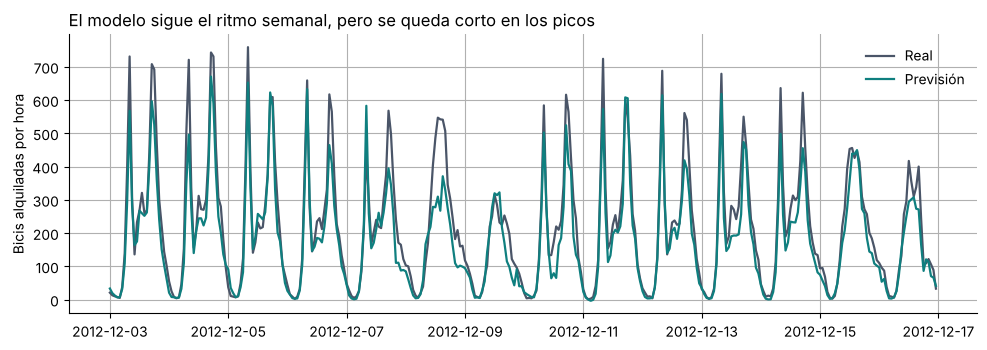

In [6]:
# Figura 1: dos semanas del test, lo real frente a lo previsto
sem = slice("2012-12-03", "2012-12-16 23:00")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(y_test[sem].index, y_test[sem], color=COLOR["real"], lw=1.6, label="Real")
ax.plot(y_test[sem].index, pred_test[(y_test.index >= "2012-12-03") & (y_test.index < "2012-12-17")], color=COLOR["modelo"], lw=1.6, label="Previsión")
ax.set_ylabel("Bicis alquiladas por hora")
ax.set_title("El modelo sigue el ritmo semanal, pero se queda corto en los picos", loc="left", fontsize=12)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.savefig("../docs/figuras/fig1_real_vs_prevision.png", dpi=150); plt.show()

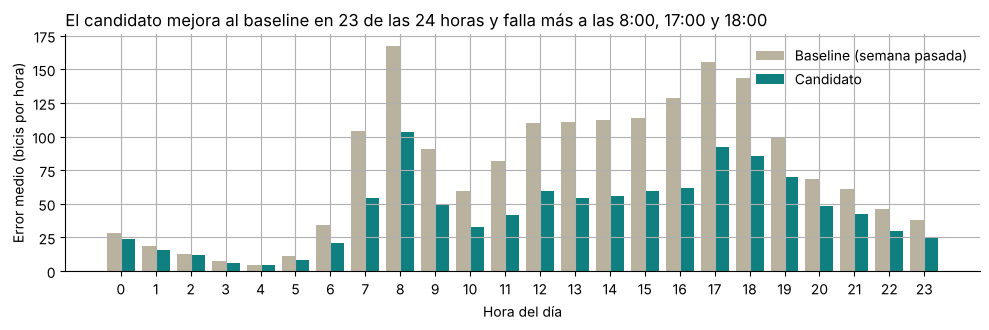

Horas con más error: [8, 17, 18] · horas en que NO mejora al baseline: [4]


In [7]:
# Figura 2: error medio por hora del día
por_hora = pd.DataFrame({"modelo": pd.Series(err_mod, index=X_test.index).groupby(X_test["hr"]).mean(),
                         "baseline": pd.Series(err_base, index=X_test.index).groupby(X_test["hr"]).mean()})
peores = por_hora["modelo"].sort_values(ascending=False).index[:3].tolist()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(por_hora.index - 0.2, por_hora["baseline"], width=0.4, color=COLOR["base"], label="Baseline (semana pasada)")
ax.bar(por_hora.index + 0.2, por_hora["modelo"], width=0.4, color=COLOR["modelo"], label="Candidato")
ax.set_xticks(range(24)); ax.set_xlabel("Hora del día"); ax.set_ylabel("Error medio (bicis por hora)")
n_mejora = int((por_hora["modelo"] < por_hora["baseline"]).sum())
ax.set_title(f"El candidato mejora al baseline en {n_mejora} de las 24 horas y falla más a las {sorted(peores)[0]}:00, {sorted(peores)[1]}:00 y {sorted(peores)[2]}:00", loc="left", fontsize=12)
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig("../docs/figuras/fig2_error_por_hora.png", dpi=150); plt.show()
print("Horas con más error:", sorted(peores), "· horas en que NO mejora al baseline:", [int(h) for h in por_hora.index[por_hora["modelo"] >= por_hora["baseline"]]])

## 4. Rendimiento por subgrupos

In [8]:
# Subgrupos: la misma métrica en cada grupo relevante
def cerca_festivo(idx):
    """1 si el día es festivo federal, su víspera o el día siguiente (el calendario se conoce de antemano)."""
    fest = USFederalHolidayCalendar().holidays(start="2010-12-01", end="2013-12-31")
    n = pd.DatetimeIndex(idx).normalize()
    return (n.isin(fest) | (n + pd.DateOffset(days=1)).isin(fest) | (n - pd.DateOffset(days=1)).isin(fest)).astype(int)

d = pd.DataFrame({"real": y_test.to_numpy(), "pred": pred_test, "punta": hp_test.to_numpy(), "lab": (X_test["workingday"] == 1).to_numpy(),
                  "tiempo": X_test["weathersit"].to_numpy(), "cerca": cerca_festivo(X_test.index) == 1}, index=X_test.index)
d["error"] = d["pred"] - d["real"]
d["abs"] = d["error"].abs()
GRUPOS = {"Todo el test": d["abs"] >= 0,
          "Laborable, hora punta": d["punta"],
          "Laborable, resto del día": d["lab"] & ~d["punta"],
          "Fin de semana y festivos": ~d["lab"],
          "Cerca de festivo": d["cerca"],
          "Tiempo despejado": d["tiempo"] == 1,
          "Nublado": d["tiempo"] == 2,
          "Lluvia o nieve": d["tiempo"] >= 3}
filas = []
for nombre, mk in GRUPOS.items():
    g = d[mk]
    filas.append({"Subgrupo": nombre, "n": int(len(g)), "MAE": g["abs"].mean(), "Sesgo": g["error"].mean(), "Nivel medio": g["real"].mean()})
sub = pd.DataFrame(filas)
sub["Diferencia con el global"] = sub["MAE"] - sub.loc[0, "MAE"]
sub["Error relativo"] = sub["MAE"] / sub["Nivel medio"]
print(sub.round(2).to_string(index=False))
print("(Sesgo = previsto − real: negativo = se queda corto)")

                Subgrupo    n   MAE  Sesgo  Nivel medio  Diferencia con el global  Error relativo
            Todo el test 1464 44.01  -5.31       188.78                      0.00            0.23
   Laborable, hora punta  240 85.53 -20.60       410.05                     41.52            0.21
Laborable, resto del día  720 27.80  -9.95       132.60                    -16.21            0.21
Fin de semana y festivos  504 47.40   8.60       163.68                      3.39            0.29
        Cerca de festivo  240 69.18  29.95       140.83                     25.17            0.49
        Tiempo despejado  824 43.96  -2.65       205.76                     -0.05            0.21
                 Nublado  543 43.40  -9.48       180.39                     -0.61            0.24
          Lluvia o nieve   97 47.84  -4.60        91.55                      3.83            0.52
(Sesgo = previsto − real: negativo = se queda corto)


## 5. Análisis de errores: dónde falla

             día   MAE  sesgo  real  previsto  cerca  laborable  tiempo_max
2012-11-23 (vie) 101.7   57.9  3910      5299   True       True         2.0
2012-11-24 (sáb)  93.8   93.2  2277      4513  False      False         2.0
2012-11-22 (jue)  87.1   84.1  2425      4444   True      False         1.0
2012-12-25 (mar)  84.4   84.4  1013      3039   True      False         3.0
2012-12-08 (sáb)  84.1  -75.6  5582      3767  False      False         2.0
2012-12-24 (lun)  83.2   83.2   920      2918   True       True         3.0
2012-12-31 (lun)  79.3   43.6  2729      3776   True       True         2.0
2012-11-21 (mié)  75.2    7.5  5146      5327   True       True         2.0
2012-12-22 (sáb)  68.4   67.2  1749      3361  False      False         1.0
2012-11-12 (lun)  64.6  -59.3  6269      4846   True      False         3.0

7 de los 10 peores días son festivo, víspera o día siguiente. Se quedan cortos o se pasan por la mitad: la gente no sigue su rutina.


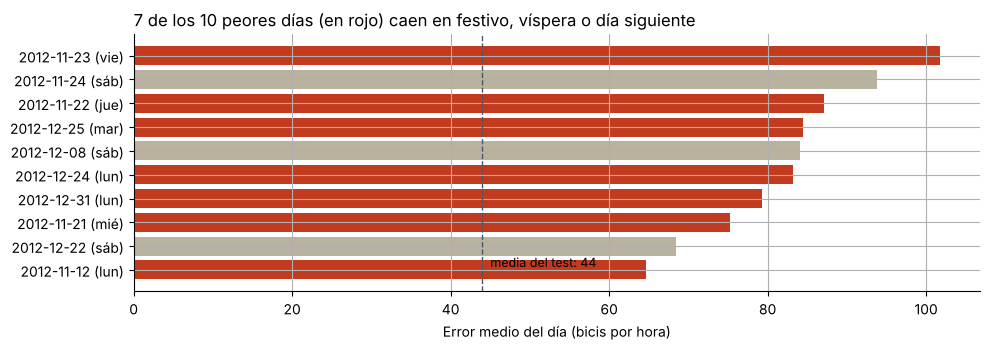

In [9]:
# Análisis de errores: los días que peor sale
dia = d.groupby(d.index.normalize()).agg(MAE=("abs", "mean"), sesgo=("error", "mean"), real=("real", "sum"), previsto=("pred", "sum"),
                                         cerca=("cerca", "max"), laborable=("lab", "max"), tiempo_max=("tiempo", "max"))
dia["real"], dia["previsto"] = dia["real"].astype(int), dia["previsto"].round().astype(int)
peores10 = dia.sort_values("MAE", ascending=False).head(10)
peores10.insert(0, "día", [f"{i.date()} ({['lun','mar','mié','jue','vie','sáb','dom'][i.dayofweek]})" for i in peores10.index])
print(peores10.reset_index(drop=True).round(1).to_string(index=False))
n_cerca = int(peores10["cerca"].sum())
print(f"\n{n_cerca} de los 10 peores días son festivo, víspera o día siguiente. Se quedan cortos o se pasan por la mitad: la gente no sigue su rutina.")

fig, ax = plt.subplots(figsize=(10, 3.6))
orden = peores10.iloc[::-1]
ax.barh(orden["día"], orden["MAE"], color=[COLOR["alerta"] if c else COLOR["base"] for c in orden["cerca"]])
ax.axvline(res["MAE"], color=COLOR["real"], ls="--", lw=1); ax.text(res["MAE"] + 1, 0, f"media del test: {res['MAE']:.0f}", fontsize=9, va="bottom")
ax.set_xlabel("Error medio del día (bicis por hora)")
ax.set_title(f"{n_cerca} de los 10 peores días (en rojo) caen en festivo, víspera o día siguiente", loc="left", fontsize=12)
plt.tight_layout(); plt.savefig("../docs/figuras/fig3_peores_dias.png", dpi=150); plt.show()

## 6. Mitigación: elegir con validación cruzada y medir el antes y el después

In [10]:
# Mitigación: tres opciones, elegidas con la validación cruzada del ENTRENAMIENTO (el test no interviene)
print("Regla fijada antes de mirar: se adopta una medida si baja el MAE de su grupo un 5 % o más en la validación cruzada y el MAE global no sube más de un 1 %.")
def hgb(**extra):
    return HistGradientBoostingRegressor(**{"max_iter": 300, "learning_rate": 0.05, "max_depth": 6, "early_stopping": False, "random_state": SEMILLA, **extra})

CV = TimeSeriesSplit(n_splits=5, test_size=int(m_val.sum()))
cerca_dev = cerca_festivo(X_dev.index) == 1
X_dev2 = X_dev.assign(cerca_festivo=cerca_festivo(X_dev.index))
punta_dev = hp_dev.to_numpy()

def validar(X, columnas, peso_punta=1.0):
    """Predicciones fuera de muestra (5 bloques temporales) y sus posiciones."""
    pos, pred = [], []
    for a, b in CV.split(X):
        w = np.where(punta_dev[a], peso_punta, 1.0)
        m = hgb().fit(X.iloc[a][columnas], y_dev.iloc[a], sample_weight=w)
        pos.append(b); pred.append(m.predict(X.iloc[b][columnas]))
    return np.concatenate(pos), np.concatenate(pred)

def resumen(pos, pred):
    e = np.abs(y_dev.to_numpy()[pos] - pred)
    return {"global": e.mean(), "hora punta": e[punta_dev[pos]].mean(), "cerca de festivo": e[cerca_dev[pos]].mean()}

opciones = {"Sin mitigación (candidato)": (X_dev, cols, 1.0),
            "Reponderar la hora punta ×2": (X_dev, cols, 2.0),
            "Reponderar la hora punta ×3": (X_dev, cols, 3.0),
            "Añadir la variable «cerca de festivo»": (X_dev2, cols + ["cerca_festivo"], 1.0)}
cv_res, oof_base = {}, None
for nombre, (X, columnas, w) in opciones.items():
    pos, pred = validar(X, columnas, w)
    cv_res[nombre] = resumen(pos, pred)
    if oof_base is None:
        oof_base = (pos, pred)
tabla_cv = pd.DataFrame(cv_res).T.round(2)
print(tabla_cv.to_string())

base_cv = cv_res["Sin mitigación (candidato)"]
decision = {}
for nombre in list(opciones)[1:]:
    grupo = "hora punta" if "Reponderar" in nombre else "cerca de festivo"
    baja = 1 - cv_res[nombre][grupo] / base_cv[grupo]
    sube = cv_res[nombre]["global"] / base_cv["global"] - 1
    decision[nombre] = {"grupo": grupo, "baja_grupo": float(baja), "sube_global": float(sube), "adoptar": bool(baja >= 0.05 and sube <= 0.01)}
    print(f"{nombre}: el MAE de «{grupo}» cambia {-baja:+.1%} y el global {sube:+.1%} → {'ADOPTAR' if decision[nombre]['adoptar'] else 'descartar'}")

Regla fijada antes de mirar: se adopta una medida si baja el MAE de su grupo un 5 % o más en la validación cruzada y el MAE global no sube más de un 1 %.


                                       global  hora punta  cerca de festivo
Sin mitigación (candidato)              40.56       74.94             48.14
Reponderar la hora punta ×2             41.44       76.47             48.29
Reponderar la hora punta ×3             41.43       77.22             48.31
Añadir la variable «cerca de festivo»   40.73       75.59             48.51
Reponderar la hora punta ×2: el MAE de «hora punta» cambia +2.0% y el global +2.2% → descartar
Reponderar la hora punta ×3: el MAE de «hora punta» cambia +3.0% y el global +2.2% → descartar
Añadir la variable «cerca de festivo»: el MAE de «cerca de festivo» cambia +0.8% y el global +0.4% → descartar


In [11]:
# Antes y después en el TEST (solo mide; no vuelve a decidir nada)
def evaluar_test(X_ent, X_prueba, columnas, peso_punta=1.0):
    w = np.where(hp_dev.to_numpy(), peso_punta, 1.0)
    m = hgb().fit(X_ent[columnas], y_dev, sample_weight=w)
    return m.predict(X_prueba[columnas])

X_test2 = X_test.assign(cerca_festivo=cerca_festivo(X_test.index))
pred_x2 = evaluar_test(X_dev, X_test, cols, 2.0)
pred_cf = evaluar_test(X_dev2, X_test2, cols + ["cerca_festivo"])
antes_despues = {}
for nombre, p in (("Sin mitigación (candidato)", pred_test), ("Reponderar la hora punta ×2", pred_x2), ("Añadir la variable «cerca de festivo»", pred_cf)):
    e = np.abs(y_test.to_numpy() - p)
    antes_despues[nombre] = {"global": float(e.mean()), "hora punta": float(e[d["punta"].to_numpy()].mean()),
                             "cerca de festivo": float(e[d["cerca"].to_numpy()].mean()),
                             "resto (sin festivo)": float(e[~d["cerca"].to_numpy()].mean())}
print(pd.DataFrame(antes_despues).T.round(2).to_string())
print("Lo que ya sabíamos por la validación cruzada: estas dos medidas no compensan. Ninguna cambia el modelo final.")

                                       global  hora punta  cerca de festivo  resto (sin festivo)
Sin mitigación (candidato)              44.01       85.53             69.18                39.07
Reponderar la hora punta ×2             44.13       83.42             69.91                39.08
Añadir la variable «cerca de festivo»   44.61       82.85             65.22                40.57
Lo que ya sabíamos por la validación cruzada: estas dos medidas no compensan. Ninguna cambia el modelo final.


Ancho único (antes): 65.3 bicis · anchos por grupo (después): {'finde_cerca0': 73.2, 'finde_cerca1': 84.7, 'laborable_cerca0': 45.2, 'laborable_cerca1': 50.7, 'punta_cerca0': 119.8, 'punta_cerca1': 110.9}
                          Antes  Después
Subgrupo                                
Todo el test               77.0     79.0
Laborable, hora punta      46.0     78.0
Laborable, resto del día   89.0     80.0
Fin de semana y festivos   75.0     79.0
Cerca de festivo           62.0     64.0
Tiempo despejado           78.0     79.0
Nublado                    78.0     79.0
Lluvia o nieve             70.0     75.0
Alerta de festivo: {'dias_marcados': 10, 'peores_marcados': 7, 'falsas_alarmas': 3}


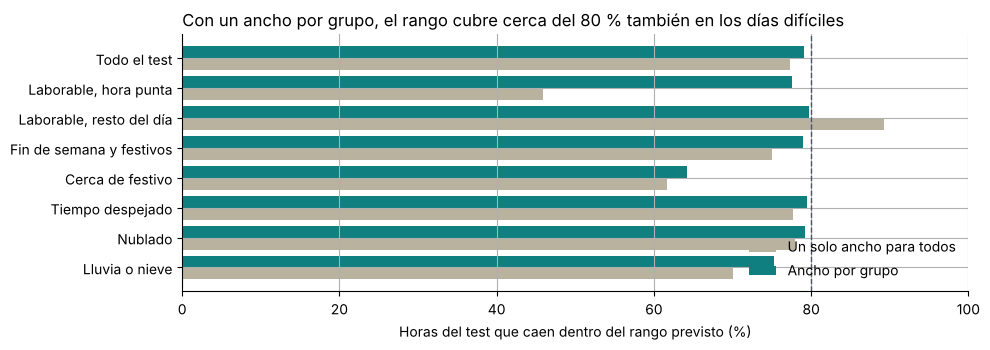

In [12]:
# Mitigación adoptada: intervalos de incertidumbre POR GRUPO (el mismo ancho para todos infravalora los días difíciles)
# El ancho de cada grupo es el percentil 80 del error absoluto fuera de muestra del ENTRENAMIENTO (validación cruzada temporal).
pos, pred_oof = oof_base
err_oof = np.abs(y_dev.to_numpy()[pos] - pred_oof)
def franja(lab, punta):
    return np.where(punta, "punta", np.where(lab, "laborable", "finde"))
lab_dev = (X_dev["workingday"] == 1).to_numpy()
clave_oof = pd.Series([f"{f}_cerca{int(c)}" for f, c in zip(franja(lab_dev[pos], punta_dev[pos]), cerca_dev[pos])])
NIVEL = 0.80
q_global = float(np.quantile(err_oof, NIVEL))
anchos = {k: round(float(np.quantile(err_oof[(clave_oof == k).to_numpy()], NIVEL)), 1) for k in sorted(clave_oof.unique())}
print("Ancho único (antes):", round(q_global, 1), "bicis · anchos por grupo (después):", anchos)

clave_test = np.array([f"{f}_cerca{int(c)}" for f, c in zip(franja(d["lab"].to_numpy(), d["punta"].to_numpy()), d["cerca"])])
q_grupo = np.array([anchos[k] for k in clave_test])
dentro_antes = (d["abs"].to_numpy() <= q_global)
dentro_despues = (d["abs"].to_numpy() <= q_grupo)
cobertura = pd.DataFrame({"Subgrupo": list(GRUPOS), "Antes": [dentro_antes[mk.to_numpy()].mean() for mk in GRUPOS.values()],
                          "Después": [dentro_despues[mk.to_numpy()].mean() for mk in GRUPOS.values()]})
print((cobertura.set_index("Subgrupo") * 100).round(0).to_string())

# La alerta «día cercano a festivo» del demostrador, medida sobre los 10 peores días
marcados = set(dia.index[dia["cerca"] == 1])
top10 = set(peores10.index)
alerta = {"dias_marcados": len(marcados), "peores_marcados": len(marcados & top10), "falsas_alarmas": len(marcados - top10)}
print("Alerta de festivo:", alerta)

fig, ax = plt.subplots(figsize=(10, 3.6))
y0 = np.arange(len(cobertura))
ax.barh(y0 + 0.2, cobertura["Antes"] * 100, height=0.4, color=COLOR["base"], label="Un solo ancho para todos")
ax.barh(y0 - 0.2, cobertura["Después"] * 100, height=0.4, color=COLOR["modelo"], label="Ancho por grupo")
ax.axvline(NIVEL * 100, color=COLOR["real"], ls="--", lw=1)
ax.set_yticks(y0); ax.set_yticklabels(cobertura["Subgrupo"]); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("Horas del test que caen dentro del rango previsto (%)")
ax.set_title("Con un ancho por grupo, el rango cubre cerca del 80 % también en los días difíciles", loc="left", fontsize=12)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig("../docs/figuras/fig4_cobertura_por_grupo.png", dpi=150); plt.show()

## 7. Riesgos que dependen de los datos

In [13]:
# Riesgos que dependen de datos: Sandy (R-03), clima con error (R-01) y horas sin fila (R-07)
es_ent = X_dev.index < FIN_ENTRENAMIENTO
modelo_val = clone(final).fit(X_dev[es_ent][cols], y_dev[es_ent])               # solo con el entrenamiento
Xv, yv = X_dev[~es_ent], y_dev[~es_ent]
pv = modelo_val.predict(Xv[cols])
sandy = Xv.index.normalize() == pd.Timestamp("2012-10-29")
mae_val_con, mae_val_sin = mae(yv, pv), mae(yv[~sandy], pv[~sandy])
sandy_real, sandy_prev = int(yv[sandy].sum()), int(round(pv[sandy].sum()))
print(f"R-03 Sandy (29/10/2012, validación): real {sandy_real} bicis en el día, previsto {sandy_prev}. MAE de la validación {mae_val_con:.1f} con ese día y {mae_val_sin:.1f} sin él.")

rng_ruido = np.random.default_rng(SEMILLA)
def con_ruido_clima(X, frac):
    X = X.copy()
    for c in ["temp", "atemp", "hum", "windspeed"]:
        X[c] = (X[c] * (1 + rng_ruido.normal(0, frac, len(X)))).clip(0, 1)
    cambia = rng_ruido.random(len(X)) < frac
    X.loc[cambia, "weathersit"] = rng_ruido.integers(1, 4, int(cambia.sum()))
    return X
mae_clima_error = mae(y_test, final.predict(con_ruido_clima(X_test[cols], 0.10)))
print(f"R-01 Clima con un 10 % de error: MAE en test {mae_clima_error:.1f} (con el clima real, {res['MAE']:.1f}).")

hueco = serie.loc[X_test.index, "hueco"].to_numpy()
mae_sin_huecos = float(np.abs(y_test.to_numpy() - pred_test)[~hueco].mean())
print(f"R-07 Horas sin fila en el test: {int(hueco.sum())} · MAE sin ellas {mae_sin_huecos:.1f} frente a {res['MAE']:.1f} con ellas.")

R-03 Sandy (29/10/2012, validación): real 22 bicis en el día, previsto 2520. MAE de la validación 42.2 con ese día y 41.1 sin él.
R-01 Clima con un 10 % de error: MAE en test 46.4 (con el clima real, 44.0).
R-07 Horas sin fila en el test: 4 · MAE sin ellas 44.1 frente a 44.0 con ellas.


## 8. Guardar lo que necesita el demostrador

In [14]:
# Lo que necesita el demostrador: modelo, histórico de la demo y metadatos (con la incertidumbre y los límites)
joblib.dump(final, "../demostrador/modelo/modelo_bicis.joblib")
columnas_demo = ["cnt", "holiday", "workingday", "weathersit", "temp", "atemp", "hum", "windspeed"]
serie.loc["2012-10-01":"2012-12-31", columnas_demo].to_csv("../demostrador/modelo/historico_demo.csv", index_label="ts")

ejemplo = final.predict(X_test.loc["2012-11-14"][cols])
metadatos = {
    "modelo": meta15["modelo"], "version": "v1.0", "entrenado": meta15["entrenado"], "semilla": SEMILLA, "datos_hash": meta15["datos_hash"],
    "variables": cols, "rango_fechas": ["2012-11-01", "2012-12-31"],
    "metricas": {"mae_test": round(res["MAE"], 1), "mae_base": round(res_b["MAE"], 1), "mae_punta": round(res["MAE hora punta"], 1),
                 "mae_cerca_festivo": round(float(sub.loc[sub["Subgrupo"] == "Cerca de festivo", "MAE"].iloc[0]), 1)},
    "incertidumbre": {"nivel": NIVEL, "anchos": anchos},
    "limitaciones": ("Solo vale para el sistema de Washington D. C. con datos de 2011–2012; hay pocos festivos, lluvias fuertes y tormentas en los datos, "
                     "y la previsión del tiempo real puede ser peor que el clima del histórico."),
    "ejemplo": {"fecha": "2012-11-14", "prevision": [round(float(v), 1) for v in np.clip(ejemplo, 0, None)]},
    "versiones": ENTORNO,
}
json.dump(metadatos, open("../demostrador/modelo/metadatos.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Guardado en demostrador/modelo/:", sorted(os.listdir("../demostrador/modelo")))
print("Tamaño del modelo:", round(os.path.getsize("../demostrador/modelo/modelo_bicis.joblib") / 1024), "KB")

Guardado en demostrador/modelo/: ['historico_demo.csv', 'metadatos.json', 'modelo_bicis.joblib']
Tamaño del modelo: 1023 KB


## 9. Cifras para la memoria, la model card y el README

In [15]:
cifras = {
    "test": {k: round(v, 3) for k, v in res.items()}, "test_base": {k: round(v, 3) for k, v in res_b.items()},
    "ic_mod": ic_mod, "ic_base": ic_base, "ic_mejora": ic_mejora, "mejora": round(1 - res["MAE"] / res_b["MAE"], 3),
    "n_test": int(len(X_test)), "dias_test": int(len(por_dia)),
    "por_hora_peores": sorted(int(h) for h in peores), "horas_sin_mejora": [int(h) for h in por_hora.index[por_hora["modelo"] >= por_hora["baseline"]]],
    "subgrupos": sub.round(3).to_dict("records"),
    "peores10": [{"dia": r["día"], "MAE": round(float(r["MAE"]), 1), "sesgo": round(float(r["sesgo"]), 1), "real": int(r["real"]), "previsto": int(r["previsto"]),
                  "cerca": bool(r["cerca"]), "tiempo": int(r["tiempo_max"])} for _, r in peores10.iterrows()],
    "n_cerca_peores": n_cerca,
    "cv": tabla_cv.to_dict("index"), "decision": decision,
    "antes_despues": {k: {kk: round(vv, 2) for kk, vv in v.items()} for k, v in antes_despues.items()},
    "nivel": NIVEL, "q_global": round(q_global, 1), "anchos": anchos,
    "cobertura": [{"Subgrupo": r["Subgrupo"], "antes": round(float(r["Antes"]), 3), "despues": round(float(r["Después"]), 3)} for _, r in cobertura.iterrows()],
    "alerta": alerta,
    "sandy": {"real": sandy_real, "previsto": sandy_prev, "mae_con": round(mae_val_con, 1), "mae_sin": round(mae_val_sin, 1)},
    "clima_error": round(mae_clima_error, 1), "huecos": {"n": int(hueco.sum()), "mae_sin": round(mae_sin_huecos, 1)},
    "kb_modelo": round(os.path.getsize("../demostrador/modelo/modelo_bicis.joblib") / 1024),
    "meta15": {"modelo": meta15["modelo"], "datos_hash": meta15["datos_hash"], "valor_test": meta15["valor_test"], "valor_validacion": meta15["valor_validacion"], "valor_cv": meta15["valor_cv"]},
    "versiones": ENTORNO,
}
print(json.dumps(cifras, ensure_ascii=False))

{"test": {"MAE": 44.009, "WAPE": 0.233, "MAE hora punta": 85.531}, "test_base": {"MAE": 75.368, "WAPE": 0.399, "MAE hora punta": 140.562}, "ic_mod": [39.4, 49.2], "ic_base": [62.6, 87.6], "ic_mejora": [0.308, 0.5], "mejora": 0.416, "n_test": 1464, "dias_test": 61, "por_hora_peores": [8, 17, 18], "horas_sin_mejora": [4], "subgrupos": [{"Subgrupo": "Todo el test", "n": 1464, "MAE": 44.009, "Sesgo": -5.311, "Nivel medio": 188.782, "Diferencia con el global": 0.0, "Error relativo": 0.233}, {"Subgrupo": "Laborable, hora punta", "n": 240, "MAE": 85.531, "Sesgo": -20.601, "Nivel medio": 410.046, "Diferencia con el global": 41.522, "Error relativo": 0.209}, {"Subgrupo": "Laborable, resto del día", "n": 720, "MAE": 27.796, "Sesgo": -9.949, "Nivel medio": 132.599, "Diferencia con el global": -16.212, "Error relativo": 0.21}, {"Subgrupo": "Fin de semana y festivos", "n": 504, "MAE": 47.397, "Sesgo": 8.597, "Nivel medio": 163.681, "Diferencia con el global": 3.388, "Error relativo": 0.29}, {"Subgr